# ResNet50: clasificación de defectos en palta Hass

El proyecto distingue PICADURA y RUSSET. La unidad de análisis es el TIFF completo de cada fruto, con tres franjas y hasta 30 vistas. Las vistas no se separan entre particiones.

| Codigo | Entrada (alto x ancho) | Cambio |
|---|---|---|
| B0 | 256 x 512 | Referencia sin aumento de datos. Ya evaluado. |
| V1 | 384 x 768 | Mayor resolución. Ya evaluado. |
| V2 | 256 x 512 | Volteo horizontal descartado porque altera el orden de captura. |
| D1 | 256 x 512 | Una copia fotométrica por fruto RUSSET en train. |
| D2 | 256 x 512 | Dos copias fotométricas por fruto RUSSET en train. |

D1 y D2 son nuevos ensayos; no se presentan como resultados obtenidos. Las copias se generan en memoria. Los TIFF originales permanecen sin cambios.

Primero ejecutar las celdas con ENTRENAR=False. Despues revisar el manifiesto de exclusiones y activar una sola corrida por vez. Los resultados disponibles de B0 y V1 se conservan.

El informe se consulta en `2. informe/Informe.ipynb`.


## 1. Configuración

Cada archivo representa una palta con tres franjas de cámaras. El pipeline conserva
la imagen completa y ajusta su tamaño a 256 × 512 píxeles (alto × ancho) con relleno,
sin recorte ni deformación. Es una propuesta inicial; la conservación de defectos
pequeños debe revisarse con las imágenes reales antes de fijar esta resolución.

`utilidades_imagenes.py` comparte la lectura RGB, la compatibilidad TIFF y el ajuste
de tamaño con Feature Engineering. Los tensores llegan al modelo en RGB, `float32`,
escala 0–255. El preprocesamiento específico de ResNet50 se aplica dentro del modelo.


Verificación de GPU

In [1]:
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("GPU detectadas:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792951750.845964   16687 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792951751.211073   16687 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792951752.878990   16687 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python: /home/tci_auto/.venvs/palta_gpu/bin/python
TensorFlow: 2.21.0
GPU detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Librerías y dataset

In [3]:
from pathlib import Path
import importlib.util

modulos = [
    "pandas", "matplotlib", "sklearn",
    "PIL", "tifffile", "skimage", "scipy"
]

for modulo in modulos:
    estado = "Instalado" if importlib.util.find_spec(modulo) else "Faltante"
    print(f"{modulo}: {estado}")

print("\nDirectorio actual:", Path.cwd())

rutas = [
    Path.cwd().parent / "DATASET_PALTA",
    Path.cwd().parent.parent / "DATASET_PALTA"
]

dataset = next((ruta for ruta in rutas if ruta.is_dir()), None)

print("Dataset encontrado:", dataset is not None)

if dataset:
    print("Ruta:", dataset)
    for conjunto in ["train", "validation", "test"]:
        for clase in ["PICADURA", "RUSSET"]:
            carpeta = dataset / conjunto / clase
            print(f"{conjunto}/{clase}:", carpeta.is_dir())

pandas: Instalado
matplotlib: Instalado
sklearn: Instalado
PIL: Instalado
tifffile: Instalado
skimage: Instalado
scipy: Instalado

Directorio actual: /mnt/c/Users/TCI_AUTO/Documents/Maestría UNI/4_2. Proyecto de Invetigación  2/PROYECTO_TI_2/6. entrenamiento
Dataset encontrado: True
Ruta: /mnt/c/Users/TCI_AUTO/Documents/Maestría UNI/4_2. Proyecto de Invetigación  2/DATASET_PALTA
train/PICADURA: True
train/RUSSET: True
validation/PICADURA: True
validation/RUSSET: True
test/PICADURA: True
test/RUSSET: True


verificar la cantidad de imágenes

In [4]:
from pathlib import Path

dataset = Path.cwd().parent.parent / "DATASET_PALTA"

total = 0

print("DISTRIBUCIÓN DEL DATASET")
print("-" * 45)

for conjunto in ["train", "validation", "test"]:
    print(f"\n{conjunto.upper()}")

    for clase in ["PICADURA", "RUSSET"]:
        carpeta = dataset / conjunto / clase

        imagenes = [
            archivo
            for archivo in carpeta.rglob("*")
            if archivo.is_file()
            and archivo.suffix.lower() in [".tif", ".tiff"]
        ]

        cantidad = len(imagenes)
        total += cantidad

        print(f"  {clase}: {cantidad} imágenes")

print("\n" + "-" * 45)
print("TOTAL:", total, "imágenes TIFF")

DISTRIBUCIÓN DEL DATASET
---------------------------------------------

TRAIN
  PICADURA: 497 imágenes
  RUSSET: 77 imágenes

VALIDATION
  PICADURA: 107 imágenes
  RUSSET: 21 imágenes

TEST
  PICADURA: 106 imágenes
  RUSSET: 21 imágenes

---------------------------------------------
TOTAL: 829 imágenes TIFF


In [6]:
from pathlib import Path, PureWindowsPath
import sys
import hashlib
import json
import random
import time
import platform
import importlib.metadata
from IPython.display import display

import numpy as np
import pandas as pd

# Encontrar la raíz desde el notebook o desde el repositorio.
RAIZ = next((ruta for ruta in [Path.cwd(), *Path.cwd().parents]
             if (ruta / "README.md").is_file()
             and (ruta / "utilidades_imagenes.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook desde la carpeta del proyecto.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from utilidades_imagenes import (
    encontrar_raiz, resolver_dataset, listar_imagenes, crear_dataset_tf,
)

RAIZ = encontrar_raiz()
RUTA_DATASET_RELATIVA = "../DATASET_PALTA"
import os
os.environ.setdefault("KERAS_HOME", str(RAIZ / ".cache" / "keras"))
SALIDA = RAIZ / "7. resultados" / "entrenamiento"
SEMILLA = 42
TAMANO_ENTRADA = (256, 512)
TAMANO_LOTE = 8
INSPECCIONAR_LOTE = False
VOLTEO_VALIDADO = False  # El responsable confirmó que debe conservarse el orden horizontal.

random.seed(SEMILLA)
np.random.seed(SEMILLA)
EXPERIMENTOS = {
    "B0": {"tamano": (256, 512), "volteo_horizontal": False},
    "V1": {"tamano": (384, 768), "volteo_horizontal": False},
    "V2": {"tamano": (256, 512), "volteo_horizontal": True},
    "D1": {"tamano": (256, 512), "volteo_horizontal": False, "copias_russet": 1},
    "D2": {"tamano": (256, 512), "volteo_horizontal": False, "copias_russet": 2},
}
print("Funciones de ResNet50. El entrenamiento se activa en la seccion 8.")

Funciones de ResNet50. El entrenamiento se activa en la seccion 8.


## 2. Datos de entrenamiento y validación

Las etiquetas se definen una vez a partir de las clases de train y se reutilizan en
validation y, al finalizar el experimento, en test. La palta completa sigue siendo
la unidad de observación. No se separan las franjas en muestras independientes.

Los archivos originales se leen desde sus particiones actuales. El notebook no
mueve, renombra ni sobrescribe imágenes.


In [7]:
def preparar_datos(excluidos=()):
    dataset = resolver_dataset(RAIZ, RUTA_DATASET_RELATIVA)
    tabla_train = listar_imagenes(dataset, "train")
    if tabla_train.empty:
        raise ValueError("Train no contiene imagenes.")
    clases = sorted(tabla_train["clase"].unique().tolist())
    if clases != ["PICADURA", "RUSSET"]:
        raise ValueError("Se esperaban las clases PICADURA y RUSSET.")
    tabla_val = listar_imagenes(dataset, "validation", clases=clases)
    tabla_train = tabla_train.loc[~tabla_train["archivo"].isin(excluidos)].reset_index(drop=True)
    tabla_val = tabla_val.loc[~tabla_val["archivo"].isin(excluidos)].reset_index(drop=True)
    for nombre, tabla in (("train", tabla_train), ("validation", tabla_val)):
        if tabla.empty or set(tabla["clase"]) != set(clases):
            raise ValueError(f"{nombre} debe conservar ambas clases despues de excluir duplicados.")
    return dataset, tabla_train, tabla_val, clases


def calcular_pesos(tabla_train, clases):
    from sklearn.utils.class_weight import compute_class_weight

    etiquetas = tabla_train["etiqueta"].to_numpy(dtype=np.int32)
    valores = np.arange(len(clases), dtype=np.int32)
    pesos = compute_class_weight("balanced", classes=valores, y=etiquetas)
    return {int(clase): float(peso) for clase, peso in zip(valores, pesos)}

### Inspección opcional de un lote

Al activar `INSPECCIONAR_LOTE` se carga un lote de train, sin aumento ni
preprocesamiento de ResNet50. Sirve para comprobar forma, rango y etiquetas.
No construye una red ni consulta imágenes de test.


In [3]:
if INSPECCIONAR_LOTE:
    import matplotlib.pyplot as plt

    dataset, tabla_train, tabla_val, clases = preparar_datos()
    datos_revision = crear_dataset_tf(
        tabla_train, dataset, tamano=TAMANO_ENTRADA,
        tamano_lote=TAMANO_LOTE, entrenamiento=False, semilla=SEMILLA,
    )
    imagenes, etiquetas = next(iter(datos_revision))
    print("Forma:", tuple(imagenes.shape), "Tipo:", imagenes.dtype.name)
    print("Rango RGB:", float(np.min(imagenes)), float(np.max(imagenes)))
    print("Clases:", {indice: clase for indice, clase in enumerate(clases)})
    plt.figure(figsize=(10, 5))
    plt.imshow(imagenes[0].numpy().astype(np.uint8))
    plt.title(clases[int(etiquetas[0])])
    plt.axis("off")
    plt.show()
else:
    print("Inspección de lote desactivada.")


Inspección de lote desactivada.


## 3. Revisión de integridad

El EDA registra dos pares exactos entre particiones y un caso con etiquetas distintas. La auditoría verifica los hashes y propone excluir cuatro archivos de las listas de entrenamiento y evaluacion. No cambia los TIFF.

Los mismos archivos elegibles se utilizan en todas las condiciones. Test se revisa solamente para integridad y permanece reservado. La auditoría no sustituye el seguimiento del fruto o lote cuando existan varios archivos del mismo fruto.


In [8]:
def hash_archivo(ruta):
    calculo = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            calculo.update(bloque)
    return calculo.hexdigest()


def firma_tabla(tabla):
    texto = "\n".join(tabla["archivo"] + ":" + tabla["sha256"])
    return hashlib.sha256(texto.encode()).hexdigest()


def leer_auditoria():
    carpeta = RAIZ / "7. resultados" / "eda"
    resumen = json.loads((carpeta / "eda_resumen.json").read_text(encoding="utf-8-sig"))
    inventario = pd.read_csv(carpeta / "eda_inventario.csv", encoding="utf-8-sig", keep_default_na=False)
    duplicados = pd.read_csv(carpeta / "eda_duplicados.csv", encoding="utf-8-sig", keep_default_na=False)
    columnas = {"archivo", "sha256", "sha_pixeles", "particion", "clase", "imagen", "error"}
    if not columnas.issubset(inventario.columns):
        raise ValueError("El inventario no contiene la auditoria necesaria.")
    if inventario.empty or inventario["archivo"].duplicated().any():
        raise ValueError("El inventario esta vacio o contiene rutas repetidas.")
    if len(inventario) != resumen["archivos"] or len(inventario) != resumen["imagenes"]:
        raise ValueError("Los conteos no coinciden. Revise el EDA.")
    if resumen["corruptas"] or inventario["error"].ne("").any():
        raise ValueError("El EDA registra errores de lectura.")
    if not inventario["imagen"].astype(str).str.lower().isin(["true", "1"]).all():
        raise ValueError("El inventario incluye archivos no reconocidos como imagenes.")
    if firma_tabla(inventario) != resumen["sha256_dataset"]:
        raise ValueError("La firma del inventario no coincide con el resumen.")
    for campo in ("sha256", "sha_pixeles"):
        if not inventario[campo].astype(str).str.fullmatch(r"[0-9a-f]{64}").all():
            raise ValueError(f"Hashes incompletos en {campo}.")
    for registro in inventario.itertuples(index=False):
        ruta = Path(registro.archivo)
        win = PureWindowsPath(registro.archivo)
        if (ruta.is_absolute() or win.drive or win.root or ".." in ruta.parts
                or "\\" in registro.archivo or len(ruta.parts) < 3):
            raise ValueError("El inventario debe usar rutas relativas dentro del dataset.")
        if ruta.parts[:2] != (registro.particion, registro.clase):
            raise ValueError(f"Ruta y etiqueta incoherentes: {registro.archivo}")
        if registro.particion not in {"train", "validation", "test"}:
            raise ValueError("Particion no reconocida.")
        if registro.clase not in {"PICADURA", "RUSSET"}:
            raise ValueError("Clase no reconocida.")

    requeridas = {"tipo", "archivo", "archivo_coincidente", "particion",
                  "particion_coincidente", "clase", "clase_coincidente"}
    if not requeridas.issubset(duplicados.columns):
        raise ValueError("El reporte de duplicados esta incompleto.")
    exactos = duplicados[duplicados["tipo"].isin(["bytes_exactos", "pixeles_exactos"])]
    indexado = inventario.set_index("archivo")
    pares_fuga, pares_conflicto, excluidos = set(), set(), set()
    for fila in exactos.itertuples(index=False):
        a, b = fila.archivo, fila.archivo_coincidente
        if a == b or a not in indexado.index or b not in indexado.index:
            raise ValueError("El reporte de duplicados contiene una ruta invalida.")
        ra, rb = indexado.loc[a], indexado.loc[b]
        if (ra.particion, rb.particion, ra.clase, rb.clase) != (
                fila.particion, fila.particion_coincidente, fila.clase, fila.clase_coincidente):
            raise ValueError("Duplicados e inventario no coinciden.")
        clave = "sha256" if fila.tipo == "bytes_exactos" else "sha_pixeles"
        if ra[clave] != rb[clave]:
            raise ValueError("El par reportado no coincide con los hashes del inventario.")
        par = tuple(sorted([a, b]))
        fuga, conflicto = ra.particion != rb.particion, ra.clase != rb.clase
        if fuga:
            pares_fuga.add(par)
        if conflicto:
            pares_conflicto.add(par)
        if fuga or conflicto:
            excluidos.update([a, b])
    if (len(pares_fuga) != resumen["pares_exactos_entre_particiones"]
            or len(pares_conflicto) != resumen["pares_exactos_etiquetas_distintas"]):
        raise ValueError("Los conteos de pares no coinciden con el resumen.")

    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].copy()
    for clave in ("sha256", "sha_pixeles"):
        grupos = elegibles.groupby(clave)[["particion", "clase"]].nunique()
        if (grupos > 1).any().any():
            raise ValueError("Persisten duplicados entre particiones o clases. Revise el EDA.")
    return resumen, inventario, sorted(excluidos)


def verificar_auditoria(dataset, aprobar_exclusiones=False):
    resumen, inventario, excluidos = leer_auditoria()
    dataset = Path(dataset).resolve()
    rutas = set(inventario["archivo"])
    locales = {p.relative_to(dataset).as_posix() for p in dataset.rglob("*") if p.is_file()}
    if locales != rutas:
        raise RuntimeError("El contenido del dataset cambio. Revise las rutas y actualice el EDA.")
    total = len(inventario)
    for numero, registro in enumerate(inventario.itertuples(index=False), 1):
        ruta = (dataset / registro.archivo).resolve()
        if not ruta.is_relative_to(dataset):
            raise ValueError("Un enlace apunta fuera del dataset.")
        if hash_archivo(ruta) != registro.sha256:
            raise RuntimeError(f"Archivo distinto al auditado: {registro.archivo}")
        if numero % 100 == 0 or numero == total:
            print(f"Integridad: {numero}/{total}")
    if excluidos and not aprobar_exclusiones:
        raise RuntimeError(
            "Integridad correcta; falta aprobar las exclusiones mostradas en la seccion 8. "
            "No se entreno ni se modificaron imagenes."
        )
    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].sort_values("archivo")
    return {
        "sha256_dataset": resumen["sha256_dataset"],
        "sha256_manifiesto": firma_tabla(elegibles),
        "exclusiones": excluidos,
        "archivos_originales": int(len(inventario)),
        "archivos_elegibles": int(len(elegibles)),
        "alcance": "Integridad exacta; independencia por fruto/lote pendiente de trazabilidad.",
    }

## 4. Modelo

ResNet50 utiliza pesos ImageNet. En B0, V1, D1 y D2 el extractor permanece congelado y se entrena la cabeza de clasificación. Se aplica `preprocess_input` una vez, con entrada RGB float32 en rango 0-255.

D1 y D2 generan copias de RUSSET con cambios leves de brillo y contraste. No hay recortes, desplazamientos, volteos ni alteraciones en el orden de las 30 vistas. Las copias se preparan solamente en train. La validación no se aumenta.

El fine-tuning parcial aparece como otra etapa, con el mismo criterio de ajuste aplicado a la condicion que se quiera comparar.


In [11]:
def construir_modelo(numero_clases, tamano=TAMANO_ENTRADA,
                      volteo_horizontal=False, semilla=SEMILLA, pesos="imagenet"):
    import tensorflow as tf
    from tensorflow.keras.applications.resnet50 import preprocess_input

    if numero_clases < 2:
        raise ValueError("El clasificador necesita al menos dos clases.")
    tf.keras.utils.set_random_seed(semilla)
    entrada = tf.keras.Input(shape=(*tamano, 3), dtype="float32", name="imagen_rgb")
    x = entrada
    if volteo_horizontal:
        x = tf.keras.layers.RandomFlip("horizontal", seed=semilla, name="aumento_train")(x)
    x = tf.keras.layers.Lambda(preprocess_input, name="preprocesamiento_resnet50")(x)
    modelo_base = tf.keras.applications.ResNet50(
        input_shape=(*tamano, 3), include_top=False, weights=pesos, pooling="avg",
    )
    modelo_base.trainable = False
    x = modelo_base(x, training=False)
    x = tf.keras.layers.Dropout(0.35, seed=semilla)(x)
    salida = tf.keras.layers.Dense(
        numero_clases, activation="softmax", name="clase",
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=semilla),
    )(x)
    modelo = tf.keras.Model(entrada, salida, name="resnet50_palta")
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return modelo

## 5. Entrenamiento con extractor congelado

Se mantienen Adam, lote 8, hasta 35 épocas, Early Stopping por `val_loss`, pesos ImageNet y una semilla fija. B0 y V1 ya se ejecutaron y sus metricas no se reemplazan.

Para D1 y D2 se extraen características de copias RUSSET generadas en memoria. El extractor sigue congelado y la cabeza entrena con originales y copias. El archivo `copias_russet_train.csv` registra los cambios aplicados; no se guarda ninguna imagen sintética.

Los pesos de clase se recalculan con el conjunto efectivo para no multiplicar dos veces el efecto del balanceo. La firma del protocolo comun conserva las condiciones originales para la comparación; el número de copias y los pesos usados se guardan aparte en la configuracion de la corrida.


In [12]:
def plan_copias_russet(tabla_train, copias, semilla=SEMILLA):
    """Registra copias de los frutos RUSSET sin alterar el inventario."""
    if not isinstance(copias, int) or copias < 0 or copias > 3:
        raise ValueError("Use entre 0 y 3 copias por fruto.")
    russet = tabla_train.loc[tabla_train["clase"] == "RUSSET", "archivo"].tolist()
    filas = []
    for archivo in russet:
        for numero in range(1, copias + 1):
            clave = f"{semilla}|{archivo}|{numero}".encode("utf-8")
            entero = int.from_bytes(hashlib.sha256(clave).digest()[:8], "big")
            rng = np.random.default_rng(entero)
            filas.append({"archivo": archivo, "copia": numero, "etiqueta": 1,
                          "brillo": float(rng.uniform(0.92, 1.08)),
                          "contraste": float(rng.uniform(0.90, 1.10))})
    return pd.DataFrame(filas, columns=["archivo", "copia", "etiqueta", "brillo", "contraste"])


def aplicar_cambio_fotometrico(matriz, mascara, brillo, contraste):
    """Cambia la intensidad y el contraste sin mover pixeles ni modificar el relleno."""
    matriz = np.asarray(matriz, dtype=np.float32)
    mascara = np.asarray(mascara, dtype=bool)
    if matriz.ndim != 3 or matriz.shape[-1] != 3 or mascara.shape != matriz.shape[:2]:
        raise ValueError("Revise las dimensiones RGB y la mascara.")
    if not (0.85 <= brillo <= 1.15 and 0.85 <= contraste <= 1.15):
        raise ValueError("El cambio solicitado esta fuera del rango previsto.")
    resultado = matriz.copy()
    if mascara.any():
        pixeles = matriz[mascara]
        media = pixeles.mean(axis=0)
        resultado[mascara] = np.clip((pixeles - media) * contraste * brillo + media * brillo, 0, 255)
    return resultado


def flujo_copias_russet(tabla_copias, dataset, tamano, lote):
    """Entrega las copias fotometricas como un flujo RGB en memoria."""
    import tensorflow as tf
    from utilidades_imagenes import cargar_rgb, ajustar_tamano

    if tabla_copias.empty:
        raise ValueError("No hay copias fotometricas para extraer.")
    dataset = Path(dataset)
    tamano = tuple(map(int, tamano))
    registros = tabla_copias.to_dict("records")

    def generar():
        for fila in registros:
            imagen = cargar_rgb(dataset / fila["archivo"])
            matriz, mascara = ajustar_tamano(imagen, tamano)
            salida = aplicar_cambio_fotometrico(matriz, mascara, fila["brillo"], fila["contraste"])
            yield salida.astype(np.float32), np.int32(fila["etiqueta"])

    estructura = (tf.TensorSpec(shape=(*tamano, 3), dtype=tf.float32),
                  tf.TensorSpec(shape=(), dtype=tf.int32))
    flujo = tf.data.Dataset.from_generator(generar, output_signature=estructura)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return flujo.with_options(opciones).batch(int(lote)).prefetch(1)


def pesos_para_etiquetas(etiquetas, clases):
    """Calcula class_weight con la distribucion efectiva de cada condicion."""
    from sklearn.utils.class_weight import compute_class_weight
    etiquetas = np.asarray(etiquetas, dtype=np.int32)
    valores = np.arange(len(clases), dtype=np.int32)
    if set(np.unique(etiquetas)) != set(valores):
        raise ValueError("El entrenamiento debe conservar ambas clases.")
    pesos = compute_class_weight("balanced", classes=valores, y=etiquetas)
    return {int(k): float(v) for k, v in zip(valores, pesos)}


In [19]:
def entrenar_resnet50(nombre_ejecucion, epocas=35, tamano=TAMANO_ENTRADA,
                      volteo_horizontal=False, aprobar_exclusiones=False,
                      semilla=SEMILLA, condicion="B0", copias_russet=0):
    if (not nombre_ejecucion or nombre_ejecucion in (".", "..")
            or Path(nombre_ejecucion).name != nombre_ejecucion
            or any(c in nombre_ejecucion for c in '<>:"/\\|?*')):
        raise ValueError("Use un nombre simple para la carpeta de resultados.")
    if not isinstance(epocas, int) or epocas < 1:
        raise ValueError("El numero de epocas debe ser un entero positivo.")
    tamano = tuple(map(int, tamano))
    if len(tamano) != 2 or min(tamano) < 32:
        raise ValueError("Revise el alto y el ancho de entrada.")
    if condicion not in EXPERIMENTOS:
        raise ValueError("Condicion desconocida.")
    if volteo_horizontal:
        raise ValueError("V2 bloqueada: el volteo invierte el orden de capturas que debe conservarse.")
    esperado = EXPERIMENTOS[condicion]
    if copias_russet != esperado.get("copias_russet", 0):
        raise ValueError("El numero de copias no coincide con la condicion.")
    if tamano != esperado["tamano"] or bool(volteo_horizontal) != esperado["volteo_horizontal"]:
        raise ValueError("Los parametros no corresponden a la condicion seleccionada.")
    carpeta = SALIDA / nombre_ejecucion
    if carpeta.exists():
        raise FileExistsError("La ejecucion ya existe. Cambie REPETICION sin borrar resultados.")
    dataset = resolver_dataset(RAIZ, RUTA_DATASET_RELATIVA)
    auditoria = verificar_auditoria(dataset, aprobar_exclusiones=aprobar_exclusiones)
    dataset, tabla_train, tabla_val, clases = preparar_datos(auditoria["exclusiones"])

    import tensorflow as tf
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)
    tf.config.experimental.enable_op_determinism()
    pesos_clases = calcular_pesos(tabla_train, clases)
    plan = plan_copias_russet(tabla_train, copias_russet, semilla)
    etiquetas_efectivas = np.concatenate([
        tabla_train["etiqueta"].to_numpy(dtype=np.int32),
        plan["etiqueta"].to_numpy(dtype=np.int32),
    ])
    pesos_fit = pesos_para_etiquetas(etiquetas_efectivas, clases)
    protocolo = {
        "arquitectura": "ResNet50 congelada + GAP + Dropout(0.35) + Dense softmax",
        "pesos_base": "imagenet", "extractor_determinista_en_memoria": True, "clases": clases,
        "sha256_dataset": auditoria["sha256_dataset"],
        "sha256_manifiesto": auditoria["sha256_manifiesto"],
        "semilla": int(semilla), "tamano_lote": int(TAMANO_LOTE),
        "epocas_maximas": epocas, "optimizer": "Adam", "learning_rate": 0.001,
        "loss": "sparse_categorical_crossentropy", "monitor": "val_loss",
        "early_stopping_patience": 7, "reduce_lr_patience": 3, "reduce_lr_factor": 0.2,
        "pesos_clases": pesos_clases,
    }
    firma_protocolo = hashlib.sha256(
        json.dumps(protocolo, sort_keys=True).encode()
    ).hexdigest()
    configuracion = {
        "condicion": condicion, "nombre_ejecucion": nombre_ejecucion,
        "tamano_entrada": list(tamano), "volteo_horizontal": bool(volteo_horizontal),
        "protocolo_comun": protocolo, "firma_protocolo": firma_protocolo,
        "exclusiones": auditoria["exclusiones"],
        "copias_russet_por_fruto": int(copias_russet),
        "n_copias_fotometricas": len(plan),
        "n_train_efectivo": len(etiquetas_efectivas),
        "pesos_fit": pesos_fit,
        "aumento": "brillo y contraste en RUSSET, fijo por copia; no se guardan imagenes" if copias_russet else "sin aumento",
        "n_train": len(tabla_train), "n_validation": len(tabla_val),
        "preprocesamiento": "RGB float32 0-255; preprocess_input dentro del modelo",
        "versiones": {p: importlib.metadata.version(p)
                      for p in ("numpy", "pandas", "Pillow", "tensorflow", "scikit-learn")},
        "python": platform.python_version(),
        "estrategia": "caracteristicas congeladas en memoria" if not volteo_horizontal else "pipeline con augmentation por epoca",
    }
    carpeta.mkdir(parents=True, exist_ok=False)
    (carpeta / "configuracion.json").write_text(
        json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8")
    (carpeta / "auditoria.json").write_text(json.dumps(auditoria, indent=2), encoding="utf-8")
    tabla_train.to_csv(carpeta / "archivos_train.csv", index=False)
    tabla_val.to_csv(carpeta / "archivos_validation.csv", index=False)
    if not plan.empty:
        plan.to_csv(carpeta / "copias_russet_train.csv", index=False)
    estado = carpeta / "estado.json"
    estado.write_text(json.dumps({"estado": "iniciado"}), encoding="utf-8")
    inicio = time.perf_counter()
    try:
        datos_train = crear_dataset_tf(
            tabla_train, dataset, tamano=tamano, tamano_lote=TAMANO_LOTE,
            entrenamiento=True, semilla=semilla)
        datos_val = crear_dataset_tf(
            tabla_val, dataset, tamano=tamano, tamano_lote=TAMANO_LOTE,
            entrenamiento=False, semilla=semilla)
        modelo = construir_modelo(len(clases), tamano, volteo_horizontal, semilla)
        # Con extractor congelado y sin augmentation, calcularlo una vez es
        # equivalente a repetirlo por época. Dropout y Dense siguen entrenándose.
        inicio_extraccion = time.perf_counter()
        modelo_fit = modelo
        if not volteo_horizontal:
            base = next(capa for capa in modelo.layers if isinstance(capa, tf.keras.Model))
            extractor = tf.keras.Model(modelo.input, modelo.layers[-2].input)
            datos_ordenados = crear_dataset_tf(tabla_train, dataset, tamano=tamano,
                tamano_lote=TAMANO_LOTE, entrenamiento=False, semilla=semilla)
            print("Extraccion real de train:", len(tabla_train), flush=True)
            class Progreso(tf.keras.callbacks.Callback):
                def on_predict_batch_end(self, batch, logs=None):
                    if batch % 10 == 0:
                        print(f"Lote de extraccion {batch + 1}", flush=True)
            caracteristicas_train = extractor.predict(datos_ordenados, verbose=2, callbacks=[Progreso()])
            print("Extraccion real de validation:", len(tabla_val), flush=True)
            caracteristicas_val = extractor.predict(datos_val, verbose=2, callbacks=[Progreso()])
            if not plan.empty:
                print("Extraccion de copias RUSSET:", len(plan), flush=True)
                flujo_copias = flujo_copias_russet(plan, dataset, tamano, TAMANO_LOTE)
                extras = extractor.predict(flujo_copias, verbose=2)
                if len(extras) != len(plan):
                    raise RuntimeError("No coinciden las caracteristicas de las copias.")
                caracteristicas_train = np.concatenate([caracteristicas_train, extras], axis=0)
            if not (np.isfinite(caracteristicas_train).all() and np.isfinite(caracteristicas_val).all()):
                raise RuntimeError("Caracteristicas no finitas")
            entrada_cabeza = tf.keras.Input(shape=(int(base.output.shape[-1]),))
            salida_cabeza = modelo.layers[-1](modelo.layers[-2](entrada_cabeza))
            modelo_fit = tf.keras.Model(entrada_cabeza, salida_cabeza)
            modelo_fit.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
            def lotes(vectores, etiquetas, barajar):
                ds = tf.data.Dataset.from_tensor_slices((vectores, etiquetas))
                if barajar:
                    ds = ds.shuffle(len(vectores), seed=semilla, reshuffle_each_iteration=True)
                opciones = tf.data.Options()
                opciones.threading.private_threadpool_size = 2
                return ds.with_options(opciones).batch(TAMANO_LOTE).prefetch(1)
            datos_train = lotes(caracteristicas_train, etiquetas_efectivas, True)
            datos_val = lotes(caracteristicas_val, tabla_val.etiqueta.to_numpy(), False)
            # Comprobar el modelo con las primeras imagenes originales.
            lote_rgb, _ = next(iter(datos_ordenados))
            np.testing.assert_allclose(modelo(lote_rgb, training=False).numpy(),
                modelo_fit(caracteristicas_train[:len(lote_rgb)], training=False).numpy(),
                rtol=1e-3, atol=1e-4)
        segundos_extraccion = time.perf_counter() - inicio_extraccion
        inicio_cabeza = time.perf_counter()
        checkpoint = carpeta / "mejor_cabeza.weights.h5"
        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
            tf.keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss",
                                               save_best_only=True, save_weights_only=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3),
            tf.keras.callbacks.CSVLogger(str(carpeta / "historial.csv")),
            tf.keras.callbacks.TerminateOnNaN(),
        ]
        historial = modelo_fit.fit(datos_train, validation_data=datos_val, epochs=epocas,
                               class_weight=pesos_fit, callbacks=callbacks)
        if not all(np.isfinite(v).all() for v in historial.history.values()):
            raise RuntimeError("Se encontraron metricas no finitas durante el entrenamiento.")
        modelo_fit.load_weights(str(checkpoint))
        pd.DataFrame(historial.history).to_csv(carpeta / "historial.csv", index=False)
        estado.write_text(json.dumps({"estado": "entrenamiento_completo",
                                      "segundos": time.perf_counter() - inicio,
                                      "segundos_extraccion": segundos_extraccion,
                                      "segundos_cabeza": time.perf_counter() - inicio_cabeza,
                                      "epocas": len(historial.history["loss"]),
                                      "mejor_epoca_val_loss": int(np.argmin(historial.history["val_loss"])) + 1,
                                      "memoria_pico_proceso_mib": getattr(
                                          __import__("psutil").Process().memory_info(), "peak_wset",
                                          __import__("psutil").Process().memory_info().rss) / 2**20}), encoding="utf-8")
    except (Exception, KeyboardInterrupt) as error:
        estado.write_text(json.dumps({"estado": "incompleto", "detalle": str(error), "traceback": __import__("traceback").format_exc()}), encoding="utf-8")
        raise
    return {"modelo": modelo, "historial": historial, "carpeta": carpeta,
            "clases": clases, "tamano_entrada": tamano, "semilla": semilla,
            "sha256_dataset": auditoria["sha256_dataset"],
            "auditoria": auditoria, "configuracion": configuracion,
            "tabla_val": tabla_val, "dataset": dataset}

## 6. Curvas de entrenamiento

Las curvas se calculan a partir de una ejecución real. No hay métricas ni resultados
simulados en este notebook.


In [14]:
def graficar_curvas(historial, carpeta=None):
    import matplotlib.pyplot as plt

    figuras = []
    valores = historial.history
    for metrica, titulo in (("loss", "Perdida"), ("accuracy", "Accuracy")):
        figura, eje = plt.subplots(figsize=(7, 4))
        epocas = np.arange(1, len(valores[metrica]) + 1)
        eje.plot(epocas, valores[metrica], label="Train")
        eje.plot(epocas, valores[f"val_{metrica}"], label="Validation")
        eje.set(xlabel="Epoca", ylabel=titulo, title=titulo)
        eje.grid(alpha=0.3)
        eje.legend()
        figura.tight_layout()
        if carpeta is not None:
            figura.savefig(Path(carpeta) / f"curva_{metrica}.png", dpi=150)
        plt.show()
        figuras.append(figura)
        plt.close(figura)
    return figuras

## 7. Evaluación de validation y test reservado

El informe compara B0 y las variantes sobre validation, con macro-F1, balanced
accuracy, precisión, recall y F1 por clase. Se guardan las predicciones por archivo
para comprobar los errores. Los valores se generan únicamente con una ejecución
real; no hay métricas de ejemplo en los CSV.

La función `evaluar_test` se conserva para la evaluación final, pero no se llama
en este notebook. Test no participa en la elección de variantes. El umbral no se
optimiza: se utiliza `argmax` de la salida softmax. Las exclusiones aprobadas también
se aplican a test cuando corresponda evaluarlo.

In [15]:
def evaluar_particion(experimento, particion="validation"):
    import matplotlib.pyplot as plt
    from sklearn.metrics import (
        classification_report, confusion_matrix, ConfusionMatrixDisplay,
        balanced_accuracy_score, f1_score, accuracy_score,
    )
    if particion not in {"validation", "test"}:
        raise ValueError("Use validation o test.")
    dataset = resolver_dataset(RAIZ, RUTA_DATASET_RELATIVA)
    auditoria = verificar_auditoria(dataset, aprobar_exclusiones=True)
    if auditoria != experimento["auditoria"]:
        raise RuntimeError("El dataset o las exclusiones cambiaron respecto al entrenamiento.")
    clases = experimento["clases"]
    tabla = listar_imagenes(dataset, particion, clases=clases)
    tabla = tabla.loc[~tabla["archivo"].isin(auditoria["exclusiones"])].reset_index(drop=True)
    if tabla.empty or set(tabla["clase"]) != set(clases):
        raise ValueError("La evaluacion debe conservar ambas clases.")
    datos = crear_dataset_tf(
        tabla, dataset, tamano=experimento["tamano_entrada"],
        tamano_lote=experimento["configuracion"]["protocolo_comun"]["tamano_lote"],
        entrenamiento=False, semilla=experimento["semilla"],
    )
    probabilidades = np.asarray(experimento["modelo"].predict(datos, verbose=0))
    if probabilidades.shape != (len(tabla), len(clases)) or not np.isfinite(probabilidades).all():
        raise RuntimeError("Forma o valores de prediccion invalidos.")
    predicciones = np.argmax(probabilidades, axis=1)
    verdaderos = tabla["etiqueta"].to_numpy(dtype=np.int32)
    indices = np.arange(len(clases))
    reporte = classification_report(verdaderos, predicciones, labels=indices,
                                    target_names=clases, output_dict=True, zero_division=0)
    configuracion = experimento["configuracion"]
    metricas = {
        "estado": "completo", "particion": particion, "n_imagenes": len(tabla),
        "condicion": configuracion["condicion"],
        "nombre_ejecucion": configuracion["nombre_ejecucion"],
        "firma_protocolo": configuracion["firma_protocolo"],
        "accuracy": float(accuracy_score(verdaderos, predicciones)),
        "macro_f1": float(f1_score(verdaderos, predicciones, labels=indices,
                                    average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(verdaderos, predicciones)),
        "recall_picadura": float(reporte["PICADURA"]["recall"]),
        "recall_russet": float(reporte["RUSSET"]["recall"]),
    }
    carpeta = experimento["carpeta"]
    pd.DataFrame(reporte).transpose().to_csv(carpeta / f"metricas_por_clase_{particion}.csv")
    resultados = tabla[["archivo", "clase", "etiqueta"]].copy()
    resultados["prediccion"] = [clases[indice] for indice in predicciones]
    for indice, clase in enumerate(clases):
        resultados[f"probabilidad_{clase}"] = probabilidades[:, indice]
    resultados.to_csv(carpeta / f"predicciones_{particion}.csv", index=False)
    matriz = confusion_matrix(verdaderos, predicciones, labels=indices)
    pd.DataFrame(matriz, index=clases, columns=clases).to_csv(carpeta / f"matriz_confusion_{particion}.csv")
    grafico = ConfusionMatrixDisplay(matriz, display_labels=clases).plot()
    grafico.ax_.set_title(f"{configuracion['condicion']} - {particion}")
    grafico.figure_.tight_layout()
    grafico.figure_.savefig(carpeta / f"matriz_confusion_{particion}.png", dpi=150)
    plt.show()
    plt.close(grafico.figure_)
    (carpeta / f"metricas_{particion}.json").write_text(
        json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(pd.DataFrame(reporte).transpose().round(4))
    return metricas, resultados


def evaluar_validacion(experimento):
    return evaluar_particion(experimento, "validation")


def evaluar_test(experimento):
    return evaluar_particion(experimento, "test")

## 8. Ejecución de la comparación

1. Abrir el notebook con el kernel `palta` y ejecutar todas las celdas con `ENTRENAR = False`.
2. Revisar los archivos del manifiesto. Con `REVISAR_INTEGRIDAD = True` y `APROBAR_EXCLUSIONES = True`, comprobar los hashes locales antes de entrenar.
3. Elegir D1 en la celda de control. Activar `ENTRENAR = True` y ejecutar solo esa celda. Se generan 77 copias de RUSSET en memoria.
4. Para D2, cambiar `CONDICION` y ejecutar con otra carpeta de resultados. Se generan 154 copias.
5. Dejar `ENTRENAR = False` al terminar. Ejecutar la comparación y despues abrir `2. informe/Informe.ipynb`.

B0 y V1 ya tienen resultados en `7. resultados/entrenamiento/`. Para repetirlos, utilizar otro identificador `REPETICION` y conservar la misma semilla y protocolo. No reemplazar las corridas originales.

Test queda reservado. D1 y D2 no se ejecutan automaticamente al abrir este notebook.


In [9]:
# Propuesta basada en los reportes guardados, sin abrir TIFF.
resumen_eda, inventario_eda, propuesta_exclusiones = leer_auditoria()
print("Archivos propuestos para excluir solo del experimento:")
display(inventario_eda.loc[inventario_eda["archivo"].isin(propuesta_exclusiones),
                           ["archivo", "particion", "clase"]])
conteos_originales = inventario_eda.groupby("particion").size()
conteos_elegibles = inventario_eda.loc[
    ~inventario_eda["archivo"].isin(propuesta_exclusiones)
].groupby("particion").size()
display(pd.DataFrame({"original": conteos_originales, "elegible_propuesto": conteos_elegibles})
        .reindex(["train", "validation", "test"]))
print("No se modificaron imagenes. Falta validar integridad local y aprobar la propuesta.")

Archivos propuestos para excluir solo del experimento:


,archivo,particion,clase
111,test/RUSSET/704F3E54-250612-145719-5.RGB.tiff,test,RUSSET
136,train/PICADURA/704F3E54-250505-153013-0.RGB.tiff,train,PICADURA
169,train/PICADURA/704F3E54-250612-145719-5.RGB.tiff,train,PICADURA
807,validation/PICADURA/defecto.RGB.tiff,validation,PICADURA


,original,elegible_propuesto
particion,,
train,574,572
validation,128,127
test,127,126


No se modificaron imagenes. Falta validar integridad local y aprobar la propuesta.


Integridad: 100/829
Integridad: 200/829
Integridad: 300/829
Integridad: 400/829
Integridad: 500/829
Integridad: 600/829
Integridad: 700/829
Integridad: 800/829
Integridad: 829/829
Extraccion real de train: 572


E0000 00:00:1792962621.379591   16687 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


Lote de extraccion 1
Lote de extraccion 11
Lote de extraccion 21
Lote de extraccion 31
Lote de extraccion 41
Lote de extraccion 51
Lote de extraccion 61
Lote de extraccion 71
72/72 - 39s - 542ms/step
Extraccion real de validation: 127


E0000 00:00:1792962660.442457   16687 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


Lote de extraccion 1
Lote de extraccion 11
16/16 - 11s - 690ms/step
Extraccion de copias RUSSET: 154
20/20 - 12s - 575ms/step


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Epoch 1/35


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6625 - loss: 0.6854 - val_accuracy: 0.8583 - val_loss: 0.3693 - learning_rate: 0.0010
Epoch 2/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8003 - loss: 0.4729 - val_accuracy: 0.8583 - val_loss: 0.3577 - learning_rate: 0.0010
Epoch 3/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8402 - loss: 0.3628 - val_accuracy: 0.8425 - val_loss: 0.3280 - learning_rate: 0.0010
Epoch 4/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8416 - loss: 0.3641 - val_accuracy: 0.8425 - val_loss: 0.3748 - learning_rate: 0.0010
Epoch 5/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8595 - loss: 0.3150 - val_accuracy: 0.8740 - val_loss: 0.3102 - learning_rate: 0.0010
Epoch 6/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8747 - loss: 0.2993 - val_accuracy: 0.8346 - val_loss: 0.3464 - learning_rate: 0.0010
Epoch 7/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8664 - loss: 0.3125 - val_accuracy: 0.8504 - va

E0000 00:00:1792962720.005436   16687 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


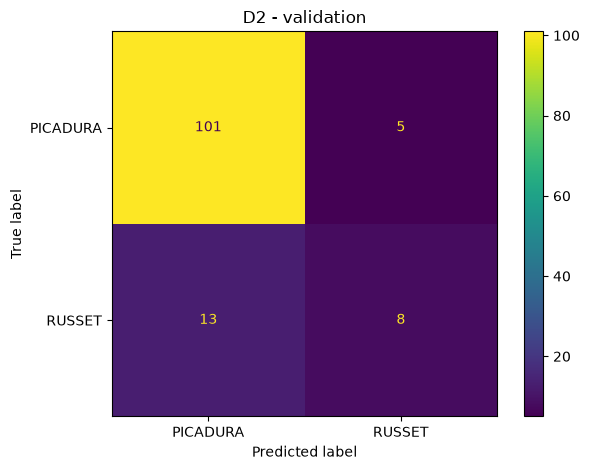

              precision  recall  f1-score   support
PICADURA         0.8860  0.9528    0.9182  106.0000
RUSSET           0.6154  0.3810    0.4706   21.0000
accuracy         0.8583  0.8583    0.8583    0.8583
macro avg        0.7507  0.6669    0.6944  127.0000
weighted avg     0.8412  0.8583    0.8442  127.0000


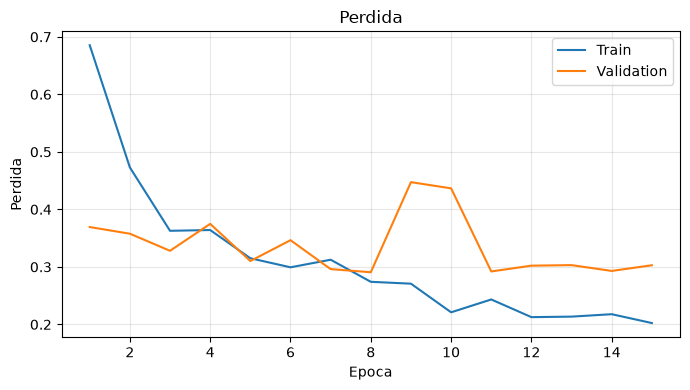

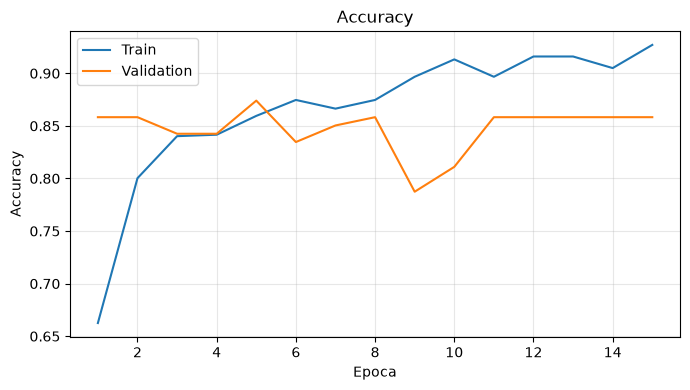

Resultados: 7. resultados/entrenamiento/D2_s42_01
Finalizado. Vuelva a dejar ENTRENAR = False antes de guardar.


In [ ]:
# Cambiar una condicion por vez.
CONDICION = "D2"                # B0, V1, D1 o D2.
REPETICION = "01"
EPOCAS = 35
APROBAR_EXCLUSIONES = True
REVISAR_INTEGRIDAD = False
ENTRENAR = False

if CONDICION not in EXPERIMENTOS:
    raise ValueError("Seleccione B0, V1, D1 o D2.")

nombre_ejecucion = f"{CONDICION}_s{SEMILLA}_{REPETICION}"

if ENTRENAR:
    parametros = EXPERIMENTOS[CONDICION]

    experimento = entrenar_resnet50(
        nombre_ejecucion,
        epocas=EPOCAS,
        tamano=parametros["tamano"],
        volteo_horizontal=parametros["volteo_horizontal"],
        aprobar_exclusiones=APROBAR_EXCLUSIONES,
        semilla=SEMILLA,
        condicion=CONDICION,
        copias_russet=parametros.get("copias_russet", 0),
    )

    metricas, predicciones = evaluar_validacion(experimento)

    graficar_curvas(
        experimento["historial"],
        experimento["carpeta"]
    )

    print(
        "Resultados:",
        experimento["carpeta"].relative_to(RAIZ).as_posix()
    )

    print(
        "Finalizado. Vuelva a dejar ENTRENAR = False antes de guardar."
    )

elif REVISAR_INTEGRIDAD:
    dataset = resolver_dataset(RAIZ, RUTA_DATASET_RELATIVA)

    auditoria = verificar_auditoria(
        dataset,
        aprobar_exclusiones=APROBAR_EXCLUSIONES
    )

    print(
        "Integridad correcta. Archivos elegibles:",
        auditoria["archivos_elegibles"]
    )

    print("No se entreno ningun modelo.")

else:
    print("Modo seguro. Seleccion:", nombre_ejecucion)
    print("Revise las exclusiones y siga los pasos de la seccion 8.")

## 9. Resultados comparables

La tabla muestra solo las corridas evaluadas sobre validation. D1 y D2 aparecen pendientes hasta que se entrenen. El cambio de macro-F1 se calcula respecto a B0.

La comparación es exploratoria: cada condicion utiliza una semilla. Las copias de RUSSET no son frutos nuevos y los resultados de test no se utilizan para escoger una variante.


In [12]:
def comparar_experimentos(semilla=SEMILLA, repeticion="01"):
    filas, firmas = [], set()
    for condicion in EXPERIMENTOS:
        nombre = f"{condicion}_s{semilla}_{repeticion}"
        carpeta = SALIDA / nombre
        ruta = carpeta / "metricas_validation.json"
        fila = {"condicion": condicion, "ejecucion": nombre, "estado": "pendiente"}
        if condicion == "V2":
            fila.update(estado="no_ejecutada", motivo="Volteo incompatible con el orden requerido de capturas")
        if ruta.is_file():
            metricas = json.loads(ruta.read_text(encoding="utf-8"))
            configuracion = json.loads((carpeta / "configuracion.json").read_text(encoding="utf-8"))
            if (metricas.get("estado") != "completo" or metricas.get("particion") != "validation"
                    or metricas.get("condicion") != condicion):
                raise ValueError(f"Resultado no valido: {nombre}")
            if (metricas["firma_protocolo"] != configuracion["firma_protocolo"]
                    or configuracion["protocolo_comun"]["semilla"] != semilla
                    or configuracion["tamano_entrada"] != list(EXPERIMENTOS[condicion]["tamano"])
                    or configuracion["volteo_horizontal"] != EXPERIMENTOS[condicion]["volteo_horizontal"]
                    or configuracion.get("copias_russet_por_fruto", 0) != EXPERIMENTOS[condicion].get("copias_russet", 0)):
                raise ValueError(f"Configuracion inconsistente: {nombre}")
            firmas.add(metricas["firma_protocolo"])
            fila["estado"] = "completo"
            for clave in ("accuracy", "macro_f1", "balanced_accuracy", "recall_picadura", "recall_russet"):
                valor = float(metricas[clave])
                if not np.isfinite(valor) or not 0 <= valor <= 1:
                    raise ValueError(f"Metrica invalida: {nombre}/{clave}")
                fila[clave] = valor
        filas.append(fila)
    if len(firmas) > 1:
        raise RuntimeError("No comparar: cambiaron el dataset, semilla o protocolo comun.")
    tabla = pd.DataFrame(filas)
    if "macro_f1" in tabla and tabla.loc[0, "estado"] == "completo":
        tabla["delta_macro_f1_vs_B0"] = tabla["macro_f1"] - tabla.loc[0, "macro_f1"]
    if firmas:
        SALIDA.mkdir(parents=True, exist_ok=True)
        tabla.to_csv(SALIDA / "comparacion_validation.csv", index=False)
    return tabla


comparacion = comparar_experimentos(semilla=SEMILLA, repeticion=REPETICION)
display(comparacion.round(4))
if (comparacion["estado"] == "completo").sum() < 2 or comparacion.loc[0, "estado"] != "completo":
    print("Falta completar B0 y al menos una variante antes de concluir la comparacion.")

,condicion,ejecucion,estado,accuracy,macro_f1,balanced_accuracy,recall_picadura,recall_russet,motivo,delta_macro_f1_vs_B0
0,B0,B0_s42_01,completo,0.8425,0.6604,0.6384,0.9434,0.3333,NaN,0.0000
1,V1,V1_s42_01,completo,0.8583,0.6598,0.6287,0.9717,0.2857,NaN,-0.0006
2,V2,V2_s42_01,no_ejecutada,NaN,NaN,NaN,NaN,NaN,Volteo incompatible con el orden requerido de ...,NaN
3,D1,D1_s42_01,pendiente,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D2,D2_s42_01,pendiente,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Archivos de resultados

Cada corrida guarda su configuracion, auditoría, CSV de entrenamiento y validación, historial, matrices de confusion, graficos y pesos de la cabeza. D1 y D2 incluyen también `copias_russet_train.csv`.

Los pesos `.h5`, el dataset original, la cache de ImageNet y los entornos virtuales no deben subirse a GitHub.


## Resultados anteriores

B0 y V1 se entrenaron sobre los archivos elegibles y se evaluaron en validation. Sus macro-F1 fueron 0.6604 y 0.6598. El recall de RUSSET fue 7/21 y 6/21, respectivamente. V2 no se ejecuto debido al orden de las capturas.

Estos resultados se conservan como referencia. D1, D2 y el fine-tuning requieren ejecución local y no tienen metricas hasta terminar sus corridas.


## 10. Comprobar GPU

Esta celda solo informa el dispositivo disponible. No instala controladores ni cambia el entorno. ResNet50 funciona en CPU; el fine-tuning de capas convolucionales tarda mas y puede requerir GPU.

En Windows con TensorFlow 2.21, una GPU NVIDIA necesita normalmente WSL2 para usarse con TensorFlow. Si el entorno muestra cero GPU, seguir con CPU o revisar WSL2 antes del ajuste fino.

In [2]:
import sys
import importlib.util
import shutil
import subprocess

print("Interprete:", sys.executable)
if importlib.util.find_spec("tensorflow") is None:
    print("TensorFlow no esta instalado en este kernel. Seleccione el entorno palta.")
else:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
    print("GPU detectadas:", [d.name for d in tf.config.list_physical_devices("GPU")])
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            print("La GPU ya estaba inicializada; se conserva su configuracion.")

if shutil.which("nvidia-smi"):
    try:
        salida = subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                                text=True, timeout=8, check=False)
        print("NVIDIA:", salida.stdout.strip() if salida.stdout.strip() else salida.stderr.strip())
    except (OSError, subprocess.TimeoutExpired) as error:
        print("No se pudo consultar nvidia-smi:", error)
else:
    print("nvidia-smi no esta disponible en esta terminal.")

Interprete: c:\Users\TCI_AUTO\venvs\palta\Scripts\python.exe
TensorFlow: 2.21.0
GPU detectadas: []
NVIDIA: GPU 0: NVIDIA GeForce RTX 3070 Ti Laptop GPU (UUID: GPU-54eecef9-c971-83dc-11f2-84452875bccf)


## 11. Fine-tuning parcial de ResNet50

El ajuste fino parte de una corrida congelada ya terminada. Recupera la cabeza guardada, libera el bloque `conv5` y mantiene las capas BatchNormalization congeladas. Se utiliza una tasa de aprendizaje pequena.

El entrenamiento vuelve a leer las imagenes en cada epoca. Para D1 o D2 incorpora las copias fotometricas en train. Validation sigue sin aumentos. El trabajo se realiza a 256 x 512 para B0 y D1, o al tamano de la condicion seleccionada.

Se recomienda comparar FT_B0 con FT_D1 utilizando el mismo lote, tasa, numero maximo de epocas y semilla. La primera comparacion B0 frente a D1 mide el efecto del cambio de datos con extractor congelado. FT_B0 frente a FT_D1 estudia ese mismo cambio despues de habilitar las ultimas capas de ResNet50.

No ejecute fine-tuning sin haber revisado la integridad de los datos ni sin una corrida congelada completa. Los checkpoints se guardan localmente y estan excluidos de Git.

Comprobar los modelos guardados

In [25]:
from pathlib import Path

carpeta_resultados = RAIZ / "7. resultados" / "entrenamiento"

for nombre in ["B0_s42_01", "D1_s42_03"]:
    carpeta = carpeta_resultados / nombre

    print(f"\nModelo: {nombre}")
    print("Carpeta:", carpeta.is_dir())

    for archivo in [
        "configuracion.json",
        "metricas_validation.json",
        "mejor_cabeza.weights.h5"
    ]:
        print(f"{archivo}:", (carpeta / archivo).is_file())


Modelo: B0_s42_01
Carpeta: True
configuracion.json: True
metricas_validation.json: True
mejor_cabeza.weights.h5: True

Modelo: D1_s42_03
Carpeta: True
configuracion.json: True
metricas_validation.json: True
mejor_cabeza.weights.h5: True


In [26]:
def ejecutar_fine_tuning(condicion, repeticion="01", epocas=8,
                         lote_ft=2, tasa=1e-5, aprobar_exclusiones=False):
    """Continua una corrida congelada ajustando conv5 con BatchNormalization fija."""
    import tensorflow as tf
    condicion = str(condicion)
    if condicion not in ("B0", "V1", "D1", "D2"):
        raise ValueError("Use B0, V1, D1 o D2.")
    if not (1 <= int(epocas) <= 25 and 1 <= int(lote_ft) <= 16 and 0 < float(tasa) <= 1e-4):
        raise ValueError("Revise epocas, lote y tasa de aprendizaje.")
    origen = SALIDA / f"{condicion}_s{SEMILLA}_{repeticion}"
    destino = SALIDA / f"FT_{condicion}_s{SEMILLA}_{repeticion}"
    if destino.exists():
        raise FileExistsError("Ya existe el ajuste fino. Use otra repeticion.")
    configuracion_origen = json.loads((origen / "configuracion.json").read_text(encoding="utf-8"))
    resultado_origen = json.loads((origen / "metricas_validation.json").read_text(encoding="utf-8"))
    if (configuracion_origen.get("condicion") != condicion or
            resultado_origen.get("estado") != "completo" or
            resultado_origen.get("particion") != "validation"):
        raise RuntimeError("Primero complete la corrida congelada y su validacion.")
    checkpoint_cabeza = origen / "mejor_cabeza.weights.h5"
    if not checkpoint_cabeza.is_file():
        raise FileNotFoundError("No se encontro el checkpoint de la cabeza.")

    dataset = resolver_dataset(RAIZ, RUTA_DATASET_RELATIVA)
    auditoria = verificar_auditoria(dataset, aprobar_exclusiones=aprobar_exclusiones)
    if (auditoria["sha256_dataset"] != configuracion_origen["protocolo_comun"]["sha256_dataset"] or
            auditoria["sha256_manifiesto"] != configuracion_origen["protocolo_comun"]["sha256_manifiesto"] or
            sorted(auditoria["exclusiones"]) != sorted(configuracion_origen["exclusiones"])):
        raise RuntimeError("El inventario no coincide con el del modelo de origen.")
    dataset, tabla_train, tabla_val, clases = preparar_datos(auditoria["exclusiones"])
    tamano = tuple(configuracion_origen["tamano_entrada"])
    copias = EXPERIMENTOS[condicion].get("copias_russet", 0)
    if configuracion_origen.get("copias_russet_por_fruto", 0) != copias:
        raise RuntimeError("El balanceo no coincide con la corrida de origen.")
    plan = plan_copias_russet(tabla_train, copias, SEMILLA)
    etiquetas = np.concatenate([tabla_train.etiqueta.to_numpy(dtype=np.int32),
                                plan.etiqueta.to_numpy(dtype=np.int32)])
    pesos_fit = pesos_para_etiquetas(etiquetas, clases)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    try:
        tf.config.experimental.enable_op_determinism()
    except (AttributeError, RuntimeError):
        pass
    modelo = construir_modelo(len(clases), tamano, False, SEMILLA)
    entrada_head = tf.keras.Input(shape=(int(modelo.layers[-2].input.shape[-1]),))
    salida_head = modelo.layers[-1](modelo.layers[-2](entrada_head))
    cabeza = tf.keras.Model(entrada_head, salida_head)
    cabeza.load_weights(str(checkpoint_cabeza))

    base = next(capa for capa in modelo.layers if isinstance(capa, tf.keras.Model))
    base.trainable = True
    for capa in base.layers:
        capa.trainable = capa.name.startswith("conv5_") and not isinstance(
            capa, tf.keras.layers.BatchNormalization)
    activas = sum(int(capa.trainable) for capa in base.layers)
    if activas < 1:
        raise RuntimeError("No se identificaron capas conv5 para ajustar.")
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(tasa)),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    train = crear_dataset_tf(tabla_train, dataset, tamano=tamano, tamano_lote=lote_ft,
                             entrenamiento=False, semilla=SEMILLA).unbatch()
    if not plan.empty:
        extras = flujo_copias_russet(plan, dataset, tamano, lote_ft).unbatch()
        train = train.concatenate(extras)
    train = train.shuffle(len(etiquetas), seed=SEMILLA,
                          reshuffle_each_iteration=True).batch(lote_ft).prefetch(1)
    validation = crear_dataset_tf(tabla_val, dataset, tamano=tamano, tamano_lote=lote_ft,
                                  entrenamiento=False, semilla=SEMILLA)

    configuracion = {
        "condicion": f"FT_{condicion}", "origen": origen.name,
        "nombre_ejecucion": destino.name, "tamano_entrada": list(tamano),
        "exclusiones": auditoria["exclusiones"],
        "copias_russet_por_fruto": copias, "n_train_efectivo": len(etiquetas),
        "pesos_fit": pesos_fit,
        "protocolo_comun": {"tamano_lote": int(lote_ft), "epocas_maximas": int(epocas),
                             "learning_rate": float(tasa), "bloque_ajustado": "conv5",
                             "batch_normalization": "congelada", "semilla": SEMILLA},
        "firma_protocolo": hashlib.sha256(json.dumps({
            "firma_original": configuracion_origen["firma_protocolo"],
            "epocas": int(epocas), "lote": int(lote_ft), "tasa": float(tasa),
            "bloque": "conv5", "semilla": SEMILLA}, sort_keys=True).encode()).hexdigest(),
    }
    destino.mkdir(parents=True, exist_ok=False)
    (destino / "configuracion.json").write_text(json.dumps(
        configuracion, ensure_ascii=False, indent=2), encoding="utf-8")
    (destino / "auditoria.json").write_text(json.dumps(auditoria, indent=2), encoding="utf-8")
    if not plan.empty:
        plan.to_csv(destino / "copias_russet_train.csv", index=False)
    estado = destino / "estado.json"
    estado.write_text(json.dumps({"estado": "iniciado"}), encoding="utf-8")
    try:
        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            tf.keras.callbacks.ModelCheckpoint(str(destino / "mejor_finetune.weights.h5"),
                monitor="val_loss", save_best_only=True, save_weights_only=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2),
            tf.keras.callbacks.CSVLogger(str(destino / "historial.csv")),
            tf.keras.callbacks.TerminateOnNaN(),
        ]
        historial = modelo.fit(train, validation_data=validation, epochs=int(epocas),
                               class_weight=pesos_fit, callbacks=callbacks)
        modelo.load_weights(str(destino / "mejor_finetune.weights.h5"))
        estado.write_text(json.dumps({"estado": "entrenamiento_completo",
            "epocas": len(historial.history["loss"]),
            "mejor_epoca_val_loss": int(np.argmin(historial.history["val_loss"])) + 1}),
            encoding="utf-8")
    except (Exception, KeyboardInterrupt) as error:
        estado.write_text(json.dumps({"estado": "incompleto", "detalle": str(error),
           "traceback": __import__("traceback").format_exc()}), encoding="utf-8")
        raise
    return {"modelo": modelo, "historial": historial, "carpeta": destino,
            "configuracion": configuracion, "auditoria": auditoria,
            "clases": clases, "tamano_entrada": tamano, "semilla": SEMILLA}


### Ejecucion opcional del fine-tuning

Dejar `EJECUTAR_FT = False` durante la revision inicial. Para comparar B0 con D1, ejecutar el ajuste fino primero sobre B0 y despues sobre D1, manteniendo los mismos valores de `EPOCAS_FT`, `LOTE_FT` y `TASA_FT`. D1 debe contar con una corrida congelada completa.

El ajuste fino puede consumir bastante memoria. Si aparece un error de memoria, cerrar el kernel y reducir `LOTE_FT` a 1. Con GPU NVIDIA en Windows, usar WSL2 y un kernel configurado con TensorFlow GPU.

Integridad: 100/829
Integridad: 200/829
Integridad: 300/829
Integridad: 400/829
Integridad: 500/829
Integridad: 600/829
Integridad: 700/829
Integridad: 800/829
Integridad: 829/829
Epoch 1/8


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1792979072.335104   16687 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef

    648/Unknown 67s 28ms/step - accuracy: 0.8657 - loss: 0.3199

/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
E0000 00:00:1792979139.377871   16687 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes wil

649/649 ━━━━━━━━━━━━━━━━━━━━ 84s 55ms/step - accuracy: 0.8659 - loss: 0.3196 - val_accuracy: 0.7480 - val_loss: 0.5408 - learning_rate: 1.0000e-05
Epoch 2/8


...

I0000 00:00:1792979576.412242   99134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:175: Filling up shuffle buffer (this may take a while): 127 of 649
I0000 00:00:1792979596.397332   99134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:175: Filling up shuffle buffer (this may take a while): 379 of 649
I0000 00:00:1792979606.412035   99134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:175: Filling up shuffle buffer (this may take a while): 501 of 649
I0000 00:00:1792979616.442481   99134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:175: Filling up shuffle buffer (this may take a while): 633 of 649
I0000 00:00:1792979618.205677   99134 shuffle_dataset_op.cc:483] Shuffle buffer filled.


649/649 ━━━━━━━━━━━━━━━━━━━━ 87s 53ms/step - accuracy: 0.9969 - loss: 0.0142 - val_accuracy: 0.8661 - val_loss: 0.6441 - learning_rate: 2.0000e-06
Epoch 8/8


I0000 00:00:1792979662.984460   99134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:175: Filling up shuffle buffer (this may take a while): 161 of 649
I0000 00:00:1792979682.970146   99134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:175: Filling up shuffle buffer (this may take a while): 477 of 649
I0000 00:00:1792979694.023208   99134 shuffle_dataset_op.cc:483] Shuffle buffer filled.


649/649 ━━━━━━━━━━━━━━━━━━━━ 71s 46ms/step - accuracy: 0.9985 - loss: 0.0054 - val_accuracy: 0.8819 - val_loss: 1.0545 - learning_rate: 2.0000e-06
Integridad: 100/829
Integridad: 200/829
Integridad: 300/829
Integridad: 400/829
Integridad: 500/829
Integridad: 600/829
Integridad: 700/829
Integridad: 800/829
Integridad: 829/829


E0000 00:00:1792979754.936023   16687 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


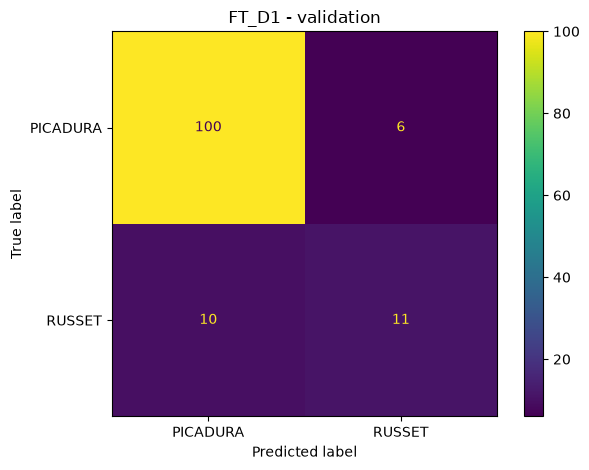

              precision  recall  f1-score  support
PICADURA         0.9091  0.9434    0.9259  106.000
RUSSET           0.6471  0.5238    0.5789   21.000
accuracy         0.8740  0.8740    0.8740    0.874
macro avg        0.7781  0.7336    0.7524  127.000
weighted avg     0.8658  0.8740    0.8686  127.000


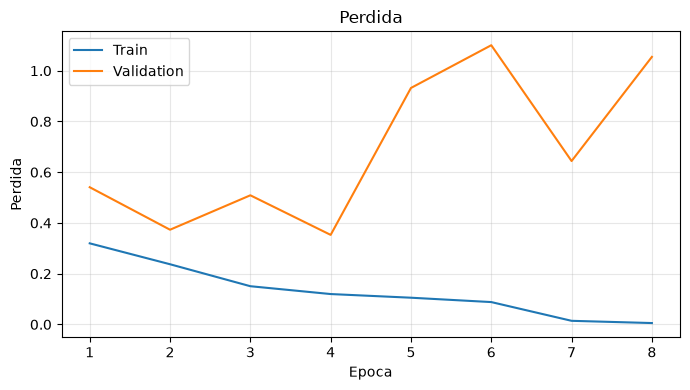

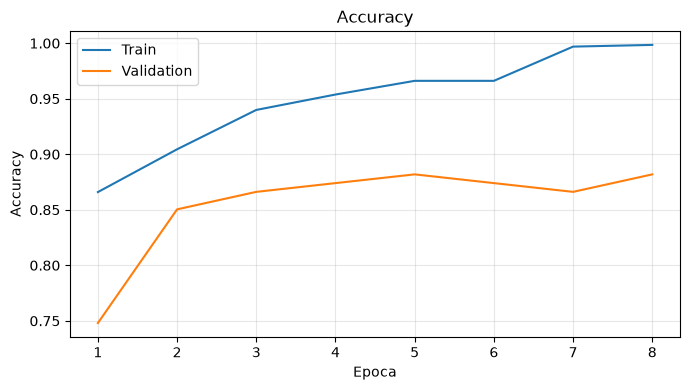

Fine-tuning terminado: 7. resultados/entrenamiento/FT_D1_s42_03


In [ ]:
EJECUTAR_FT = False
CONDICION_FT = "D1"     # B0 o D1 para la comparacion propuesta.
REPETICION_FT = "03"  # Debe existir la corrida congelada correspondiente.
EPOCAS_FT = 8
LOTE_FT = 1
TASA_FT = 1e-5
APROBAR_EXCLUSIONES_FT = True

if EJECUTAR_FT:
    ajuste = ejecutar_fine_tuning(
        CONDICION_FT, repeticion=REPETICION_FT, epocas=EPOCAS_FT,
        lote_ft=LOTE_FT, tasa=TASA_FT,
        aprobar_exclusiones=APROBAR_EXCLUSIONES_FT)
    metricas_ft, _ = evaluar_validacion(ajuste)
    graficar_curvas(ajuste["historial"], ajuste["carpeta"])
    print("Fine-tuning terminado:", ajuste["carpeta"].relative_to(RAIZ))
else:
    print("Fine-tuning desactivado. Se conservan las corridas anteriores.")

## 12. Siguiente lectura de resultados

Abrir `2. informe/Informe.ipynb` y ejecutar todas sus celdas. El informe lee automaticamente las metricas y curvas guardadas. Las condiciones sin entrenamiento terminado permanecen pendientes.

Los resultados originales B0 y V1 se conservan; D1, D2 y los ajustes finos solo aparecen cuando se ejecutan realmente.